# Comprehensive EDA: Bank Customer Segmentation
## Objective
To perform a deep exploratory data analysis on the primary `bank_transactions.csv` dataset, uncovering demographic trends, financial behaviors, and identifying potential features for the segmentation model.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import os
from datetime import datetime

# Configuration
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 6)
pd.set_option('display.float_format', lambda x: '%.3f' % x)


## 1. Data Loading and High-Level Overview


In [2]:
data_path = '../data/bank_transactions.csv'
if os.path.exists(data_path):
    df = pd.read_csv(data_path)
    print(f'Dataset successfully loaded. Shape: {df.shape}')
else:
    print('Dataset not found. Please ensure it is downloaded and placed in data/bank_transactions.csv')
    df = pd.DataFrame() # Dummy for execution safety


Dataset successfully loaded. Shape: (1048567, 9)


In [3]:
if not df.empty:
    display(df.head())
    display(df.info())
    display(df.describe(include='all'))


,TransactionID,CustomerID,CustomerDOB,CustGender,CustLocation,CustAccountBalance,TransactionDate,TransactionTime,TransactionAmount (INR)
0,T1,C5841053,10/1/94,F,JAMSHEDPUR,17819.050,2/8/16,143207,25.000
1,T2,C2142763,4/4/57,M,JHAJJAR,2270.690,2/8/16,141858,27999.000
2,T3,C4417068,26/11/96,F,MUMBAI,17874.440,2/8/16,142712,459.000
3,T4,C5342380,14/9/73,F,MUMBAI,866503.210,2/8/16,142714,2060.000
4,T5,C9031234,24/3/88,F,NAVI MUMBAI,6714.430,2/8/16,181156,1762.500


<class 'pandas.DataFrame'>
RangeIndex: 1048567 entries, 0 to 1048566
Data columns (total 9 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   TransactionID            1048567 non-null  str    
 1   CustomerID               1048567 non-null  str    
 2   CustomerDOB              1045170 non-null  str    
 3   CustGender               1047467 non-null  str    
 4   CustLocation             1048416 non-null  str    
 5   CustAccountBalance       1046198 non-null  float64
 6   TransactionDate          1048567 non-null  str    
 7   TransactionTime          1048567 non-null  int64  
 8   TransactionAmount (INR)  1048567 non-null  float64
dtypes: float64(2), int64(1), str(6)
memory usage: 110.0 MB


None

,TransactionID,CustomerID,CustomerDOB,CustGender,CustLocation,CustAccountBalance,TransactionDate,TransactionTime,TransactionAmount (INR)
count,1048567,1048567,1045170,1047467,1048416,1046198.000,1048567,1048567.000,1048567.000
unique,1048567,884265,17254,3,9355,NaN,55,NaN,NaN
top,T1,C4327447,1/1/1800,M,MUMBAI,NaN,7/8/16,NaN,NaN
freq,1,6,57339,765530,103595,NaN,27261,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,115403.540,NaN,157087.529,1574.335
std,NaN,NaN,NaN,NaN,NaN,846485.381,NaN,51261.854,6574.743
min,NaN,NaN,NaN,NaN,NaN,0.000,NaN,0.000,0.000
25%,NaN,NaN,NaN,NaN,NaN,4721.760,NaN,124030.000,161.000
50%,NaN,NaN,NaN,NaN,NaN,16792.180,NaN,164226.000,459.030
75%,NaN,NaN,NaN,NaN,NaN,57657.360,NaN,200010.000,1200.000


## 2. Data Cleaning & Missing Values Assessment
We need to identify nulls and understand if they represent a systematic issue or random missingness.


,Missing Count,Percentage
CustomerDOB,3397,0.324
CustAccountBalance,2369,0.226
CustGender,1100,0.105
CustLocation,151,0.014


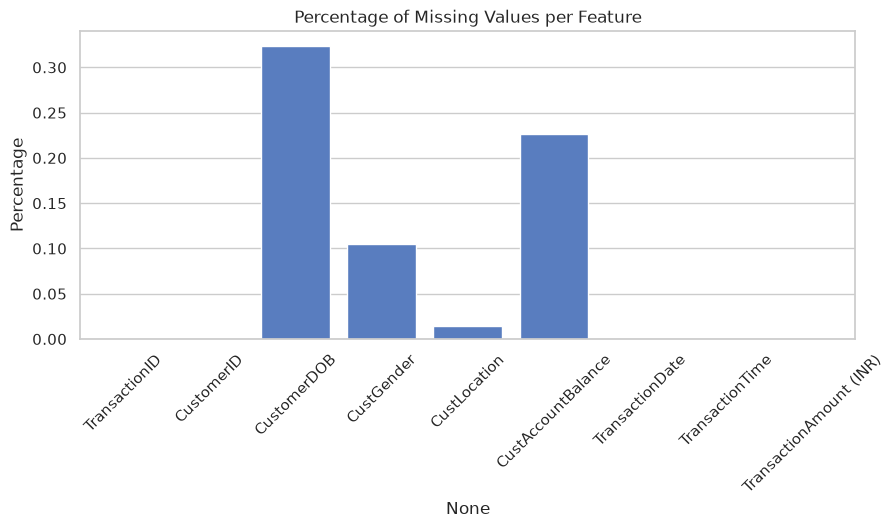

In [4]:
if not df.empty:
    missing = df.isnull().sum()
    missing_pct = (missing / len(df)) * 100
    missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage': missing_pct})
    display(missing_df[missing_df['Missing Count'] > 0].sort_values(by='Percentage', ascending=False))
    
    # Visualize missing data
    plt.figure(figsize=(10,4))
    sns.barplot(x=missing_df.index, y=missing_df['Percentage'])
    plt.title('Percentage of Missing Values per Feature')
    plt.xticks(rotation=45)
    plt.show()


## 3. Deep Univariate Analysis
Analyzing the distribution of single variables to detect skewness, outliers, and baseline demographics.


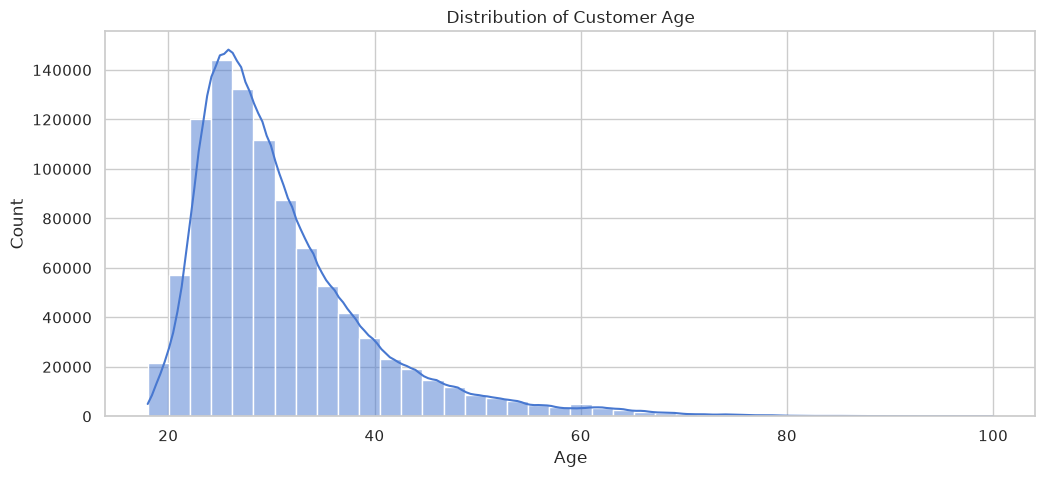

In [5]:
if not df.empty and 'CustomerDOB' in df.columns:
    # Safely parse DOB (format DD/MM/YY) and handle century wrapping
    try:
        df['DOB_parsed'] = pd.to_datetime(df['CustomerDOB'], format='%d/%m/%y', errors='coerce')
        # Pandas parses e.g., '73' as 2073. If year > 2005, it belongs to the 1900s.
        df.loc[df['DOB_parsed'].dt.year > 2005, 'DOB_parsed'] -= pd.DateOffset(years=100)
        
        # Calculate Age relative to 2016 (dataset release)
        df['Age'] = 2016 - df['DOB_parsed'].dt.year
        
        # Clean the main dataframe to remove extreme outliers globally
        df = df[(df['Age'] >= 18) & (df['Age'] <= 100)].copy()
        
        plt.figure(figsize=(12, 5))
        sns.histplot(df['Age'], bins=40, kde=True)
        plt.title('Distribution of Customer Age')
        plt.xlabel('Age')
        plt.show()
    except Exception as e:
        print(f'Could not parse DOB: {e}')

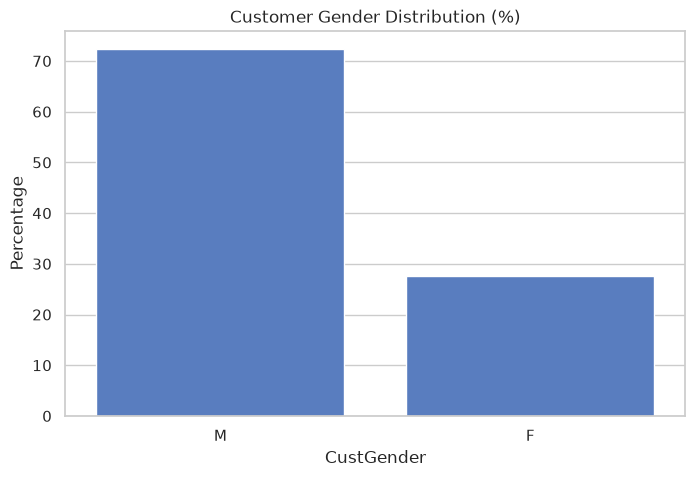

In [6]:
if not df.empty and 'CustGender' in df.columns:
    plt.figure(figsize=(8, 5))
    gender_counts = df['CustGender'].value_counts(normalize=True) * 100
    sns.barplot(x=gender_counts.index, y=gender_counts.values)
    plt.title('Customer Gender Distribution (%)')
    plt.ylabel('Percentage')
    plt.show()

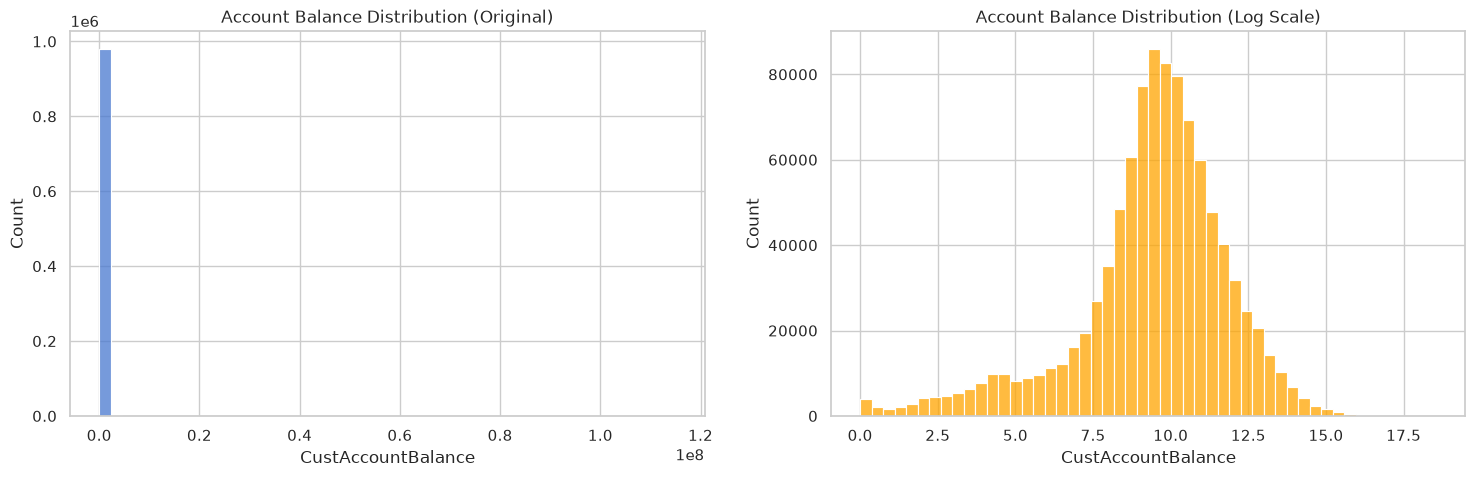

In [7]:
if not df.empty and 'CustAccountBalance' in df.columns:
    fig, axes = plt.subplots(1, 2, figsize=(18, 5))
    
    # Standard Distribution
    sns.histplot(df['CustAccountBalance'], bins=50, ax=axes[0])
    axes[0].set_title('Account Balance Distribution (Original)')
    
    # Log Transformed Distribution (handling zeros by adding 1)
    sns.histplot(np.log1p(df['CustAccountBalance']), bins=50, ax=axes[1], color='orange')
    axes[1].set_title('Account Balance Distribution (Log Scale)')
    plt.show()


## 4. Bivariate Analysis & Behavioral Profiling
How do demographics correlate with financial behavior?


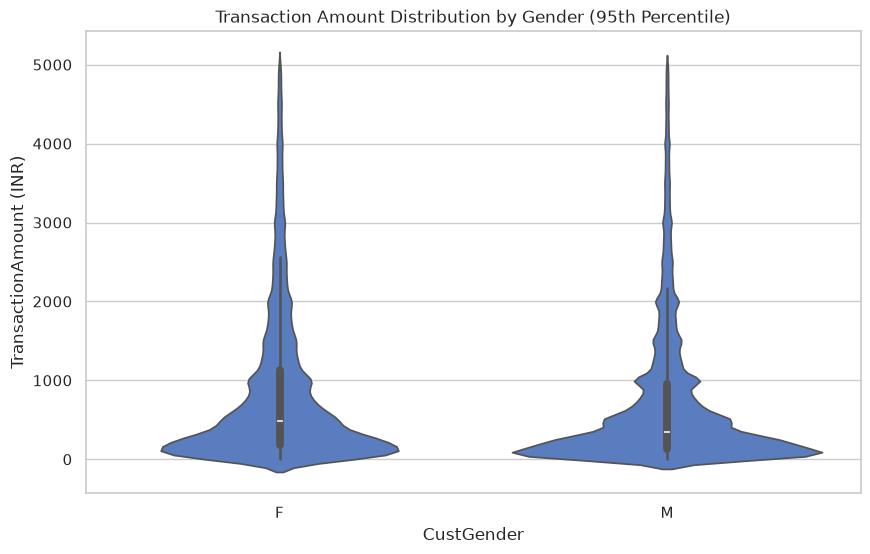

In [8]:
if not df.empty and 'CustGender' in df.columns and 'TransactionAmount (INR)' in df.columns:
    plt.figure(figsize=(10, 6))
    sns.violinplot(data=df[df['TransactionAmount (INR)'] < df['TransactionAmount (INR)'].quantile(0.95)], 
                   x='CustGender', y='TransactionAmount (INR)')
    plt.title('Transaction Amount Distribution by Gender (95th Percentile)')
    plt.show()

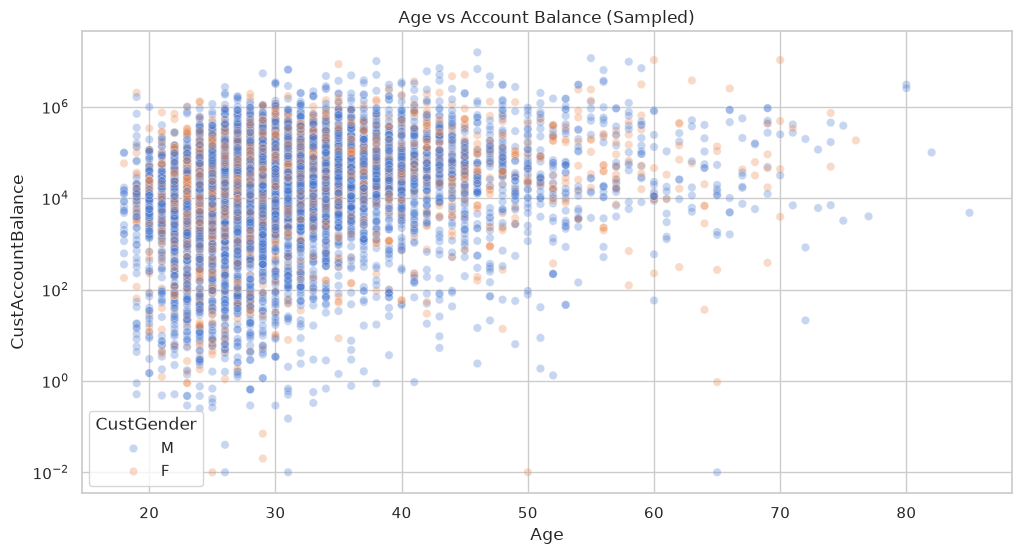

In [9]:
if not df.empty and 'Age' in df.columns and 'CustAccountBalance' in df.columns:
    # Sample data to avoid memory issues during scatter plotting
    df_sample = df.sample(n=10000, random_state=42) if len(df) > 10000 else df
    plt.figure(figsize=(12, 6))
    sns.scatterplot(data=df_sample, x='Age', y='CustAccountBalance', alpha=0.3, hue='CustGender')
    plt.yscale('log')
    plt.title('Age vs Account Balance (Sampled)')
    plt.show()

## 5. Temporal Analysis (Transaction Trends)
Analyzing when transactions occur.


/tmp/ipykernel_64171/690553930.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['TransactionDate'] = pd.to_datetime(df['TransactionDate'], errors='coerce', dayfirst=True)


/tmp/ipykernel_64171/690553930.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='TransDayOfWeek', order=day_order, palette='viridis')


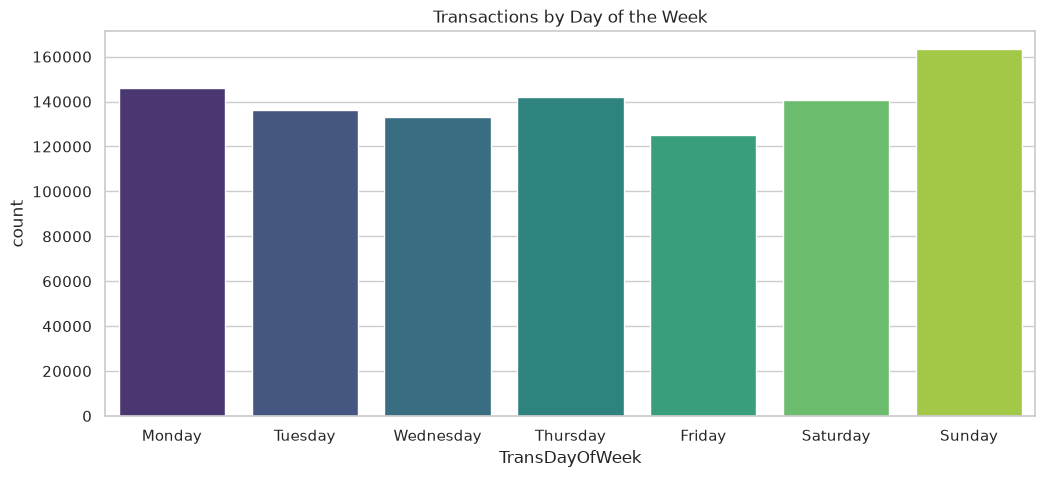

In [10]:
if not df.empty and 'TransactionDate' in df.columns:
    # Parse transaction date (format often DD/MM/YY)
    df['TransactionDate'] = pd.to_datetime(df['TransactionDate'], errors='coerce', dayfirst=True)
    
    # Extract temporal features
    df['TransMonth'] = df['TransactionDate'].dt.month
    df['TransDayOfWeek'] = df['TransactionDate'].dt.day_name()
    
    plt.figure(figsize=(12, 5))
    day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
    sns.countplot(data=df, x='TransDayOfWeek', order=day_order, palette='viridis')
    plt.title('Transactions by Day of the Week')
    plt.show()


## 6. Correlation Analysis
Understanding relationships between continuous numeric variables.


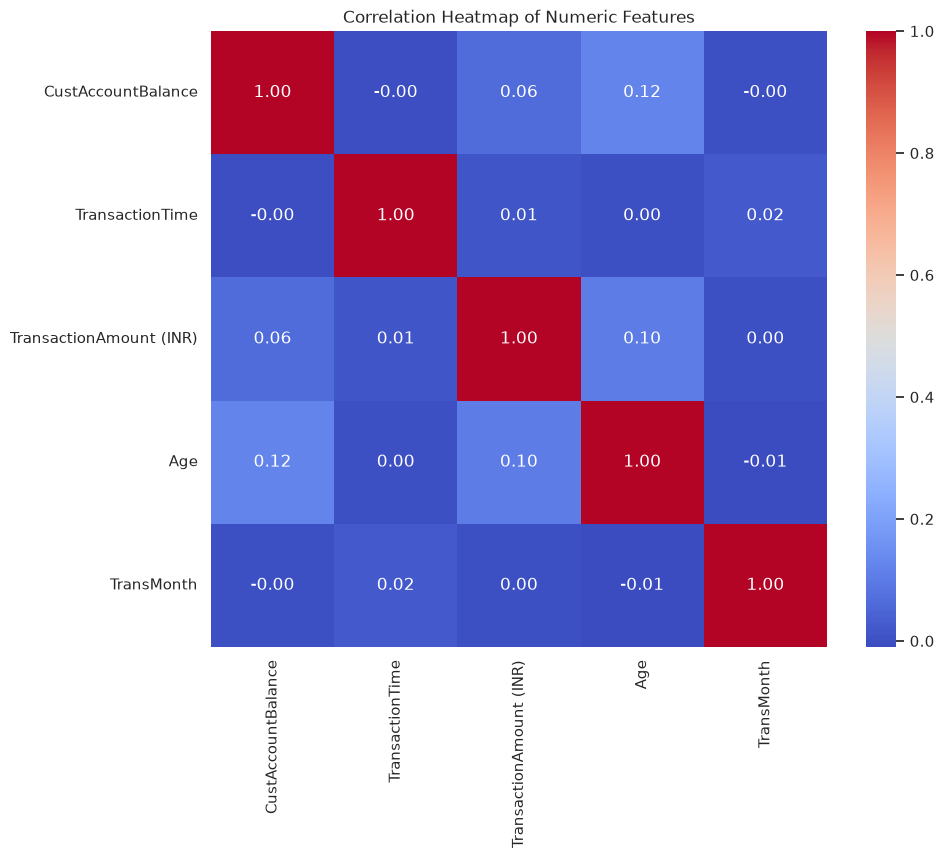

In [11]:
if not df.empty:
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    if len(numeric_cols) > 1:
        corr = df[numeric_cols].corr()
        plt.figure(figsize=(10, 8))
        sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', square=True)
        plt.title('Correlation Heatmap of Numeric Features')
        plt.show()


## Summary & Feature Engineering Next Steps
Based on the EDA, the data requires:
1. Log transformation for heavily skewed monetary features (Balance, Transaction Amount).
2. Date parsing to extract Recency (Days since last transaction) and Frequency metrics to build an RFM profile.
3. Handling of outliers in both Age and Balance columns before feeding into clustering algorithms like K-Means.


## 7. Data Normalization for Clustering
Distance-based clustering algorithms (like K-Means) and deep learning models (like Autoencoders) are highly sensitive to the scale of the features. 

For example, `CustAccountBalance` ranges into the millions, while `Age` is typically between 18 and 100. Without scaling, the model will entirely ignore age and only cluster based on balance.

We will apply **StandardScaler** to the continuous numerical features to ensure they all have a mean of 0 and a standard deviation of 1.


In [12]:
from sklearn.preprocessing import StandardScaler

if not df.empty:
    # Select continuous numerical columns for scaling
    # We exclude ID columns or categorical codes
    features_to_scale = ['Age', 'CustAccountBalance', 'TransactionAmount (INR)']
    features_to_scale = [f for f in features_to_scale if f in df.columns]
    
    # Drop NaNs for the scaling demonstration
    df_clean = df.dropna(subset=features_to_scale).copy()
    
    scaler = StandardScaler()
    df_scaled = df_clean.copy()
    df_scaled[features_to_scale] = scaler.fit_transform(df_clean[features_to_scale])
    
    print("--- Original Data Summary ---")
    display(df_clean[features_to_scale].describe())
    
    print("\n--- Scaled Data Summary (Mean ≈ 0, Std ≈ 1) ---")
    display(df_scaled[features_to_scale].describe())
    
    print("\nData is now normalized and ready for clustering pipeline input!")


--- Original Data Summary ---


,Age,CustAccountBalance,TransactionAmount (INR)
count,984047.000,984047.000,984047.000
mean,31.062,106164.295,1452.114
std,8.748,818423.330,6140.987
min,18.000,0.000,0.000
25%,25.000,4589.050,151.000
50%,29.000,16025.160,431.000
75%,34.000,53818.490,1125.000
max,100.000,115035495.100,1560034.990



--- Scaled Data Summary (Mean ≈ 0, Std ≈ 1) ---


,Age,CustAccountBalance,TransactionAmount (INR)
count,984047.000,984047.000,984047.000
mean,0.000,-0.000,-0.000
std,1.000,1.000,1.000
min,-1.493,-0.130,-0.236
25%,-0.693,-0.124,-0.212
50%,-0.236,-0.110,-0.166
75%,0.336,-0.064,-0.053
max,7.880,140.428,253.800



Data is now normalized and ready for clustering pipeline input!
